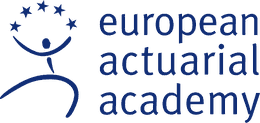

<h1 style="color:#0F2B72;">Fit4AI compact</h1>
<h2 style="color:#0F2B72;">Module 6: Unsupervised Learning</h2>
<div style="border:0px; background-color:#0F2B72; width:100%; height:1px;">&nbsp;</div>
<h4 style="color:#0F2B72;" class="unlisted unnumbered">EAA Inhouse Seminar SAV | Zurich, 19/20 November 2026</h4>
<p style="color:#0F2B72;">Dr Johannes Schupp<br>Jupyter Notebook (Python)</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/fit4ai-compact-20261119/blob/main/Fit4AI_6_Unsupervised_Learning.ipynb)

Repository: [simonhatzesberger/fit4ai-compact-20261119](https://github.com/simonhatzesberger/fit4ai-compact-20261119) – code under the [MIT License](https://github.com/simonhatzesberger/fit4ai-compact-20261119/blob/main/LICENSE).

In [1]:
# --- Setup: Google Colab or local Python environment
# In Google Colab, all required packages are preinstalled (seaborn and ipywidgets
# are installed only if they are missing), and the widget manager for the
# interactive figures is enabled. Locally: pip install -r requirements.txt
import importlib.util
import subprocess
import sys

try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    for pkg in ["seaborn", "ipywidgets"]:
        if importlib.util.find_spec(pkg) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# Course repository: data files that are missing locally are downloaded from here
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main"

# --- Load required libraries

# Limiting the number of threads to avoid a known KMeans/MKL issue on Windows
import os
os.environ["OMP_NUM_THREADS"] = "1" 
os.environ["MKL_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL.*"
)

# Essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial import ConvexHull
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import MDS
from sklearn.datasets import make_blobs, make_moons, make_circles

from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator
from ipywidgets import interact, IntSlider, Dropdown

# Colour palette for the interactive visualisations (blue as primary colour)
PRIMARY, ACCENT_RED, ACCENT_GREEN, GRAY_TEXT = "#0050A0", "#C0504D", "#4E7C59", "#404040"
CLUSTER_COLORS = [PRIMARY, ACCENT_RED, ACCENT_GREEN, "#7A8DA8", "#9C7A7A"]

<div style="border:0px; background-color:#0050A0; width:100%; height:1px;">&nbsp;</div>
<h2 style="color:#0050A0;">Part 1 on cluster analysis – simulated data</h2>

In [2]:
# --- Simulation of data with three clusters from bivariate normal distributions

np.random.seed(2025)  # Seed for reproducibility

n = 200 # Sample size

# Random assignment to the three clusters with equal probability
clust = np.random.choice([1,2,3], size=n, p=[1/3,1/3,1/3])

# Means and covariance matrices for the three clusters
mu1 = np.array([2.0, 3.0])
Sigma1 = np.array([[2.0, -2.0], [-2.0, 4.0]])

mu2 = np.array([3.0, -2.0])
Sigma2 = np.array([[1.0, 0.0], [0.0, 1.0]])

mu3 = np.array([-1.0, 1.0])
Sigma3 = np.array([[1.0, -0.5], [-0.5, 2.0]])

# Simulation 
rows = []
for i in range(n):
    if clust[i] == 1:
        X1,X2 = np.random.multivariate_normal(mean=mu1, cov=Sigma1)
    elif clust[i] == 2:
        X1,X2 = np.random.multivariate_normal(mean=mu2, cov=Sigma2)
    else:
        X1,X2 = np.random.multivariate_normal(mean=mu3, cov=Sigma3)
    rows.append({'clust': int(clust[i]), 'X1': X1, 'X2': X2})

df_sim = pd.DataFrame(rows)
df_sim['clust'] = df_sim['clust'].astype('category')  

print("\nSimulated data with three clusters:\n")
df_sim.head()



Simulated data with three clusters:



,clust,X1,X2
0,1,1.595531,4.039229
1,3,-0.176926,-1.250643
2,3,-0.938631,1.095234
3,2,3.577569,-2.843591
4,2,2.514615,-2.759943



Simulated data with true cluster membership:



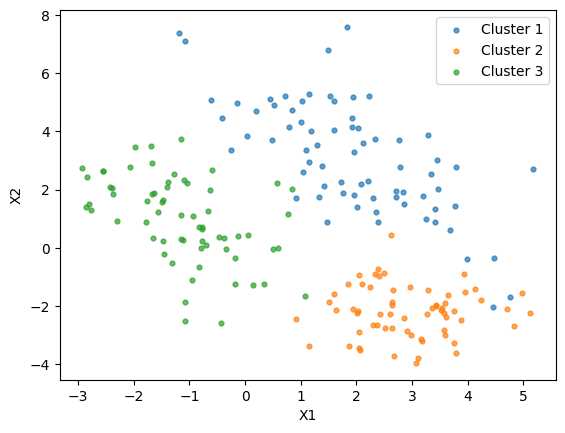

In [3]:
# --- Scatter plot of the simulated data 

fig, ax = plt.subplots()
for label in sorted(df_sim['clust'].unique()):
    sub = df_sim[df_sim['clust'] == label]
    ax.scatter(sub['X1'], sub['X2'], label=f'Cluster {label}', alpha=0.7, s=12)

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_title('')
ax.legend()

#plt.savefig("sim_data_cluster.png", dpi=300, bbox_inches="tight")

print("\nSimulated data with true cluster membership:\n")
plt.show()


Dendrograms of the hierarchical clustering methods with a cut for k clusters and corresponding colouring:



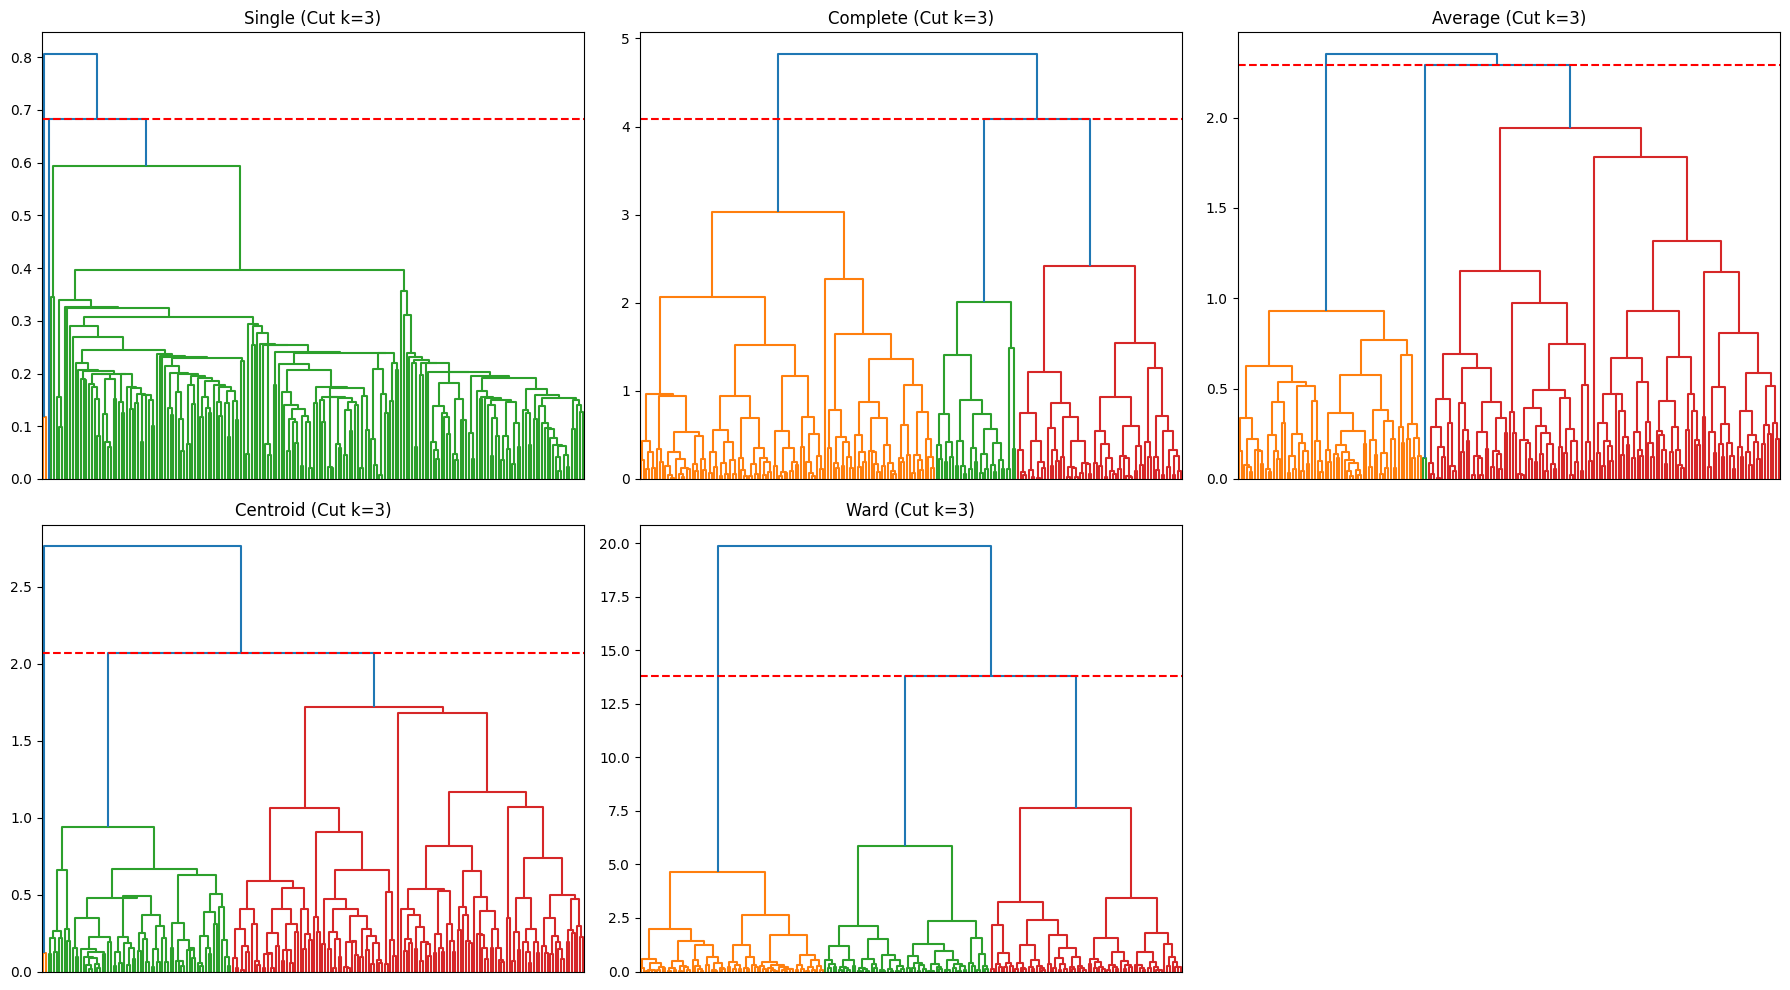

In [4]:
# --- Agglomerative (hierarchical) cluster analysis

X = df_sim[['X1','X2']].values
scaler = StandardScaler()
X_std = scaler.fit_transform(X)  # Standardisation 

# Methods
methods = ['single', 'complete', 'average', 'centroid', 'ward']
#methods = ['ward']
linkages = {
    m: linkage(X_std, method=m)
    for m in methods
}

# Plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10)) 
axes = axes.flatten()

k = 3  # "desired" number of clusters

for ax, method in zip(axes, methods):
    Z = linkages[method]
    
    thresh = Z[-k+1, 2]  # Height for the cut line at k
    
    dendrogram(
        Z,
        ax=ax,
        no_labels=True,
        color_threshold=thresh,     # Cluster colours for k clusters
    )
    
    ax.axhline(y=thresh, color="red", linestyle="--", linewidth=1.5) # Draw the cut line
    
    ax.set_title(f"{method.capitalize()} (Cut k=3)")

for j in range(len(methods), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

#plt.savefig("dendrogram_hierarchical.png", dpi=300, bbox_inches="tight")

print("\nDendrograms of the hierarchical clustering methods with a cut for k clusters and corresponding colouring:\n")
plt.show()


**Interpretation**

The complete linkage and Ward methods suggest three clusters. For the single linkage, average linkage and centroid methods, the dendrogram shows only two distinct clusters in each case, or the third cluster contains only a few elements.


Simulated data with hierarchical and true cluster membership:



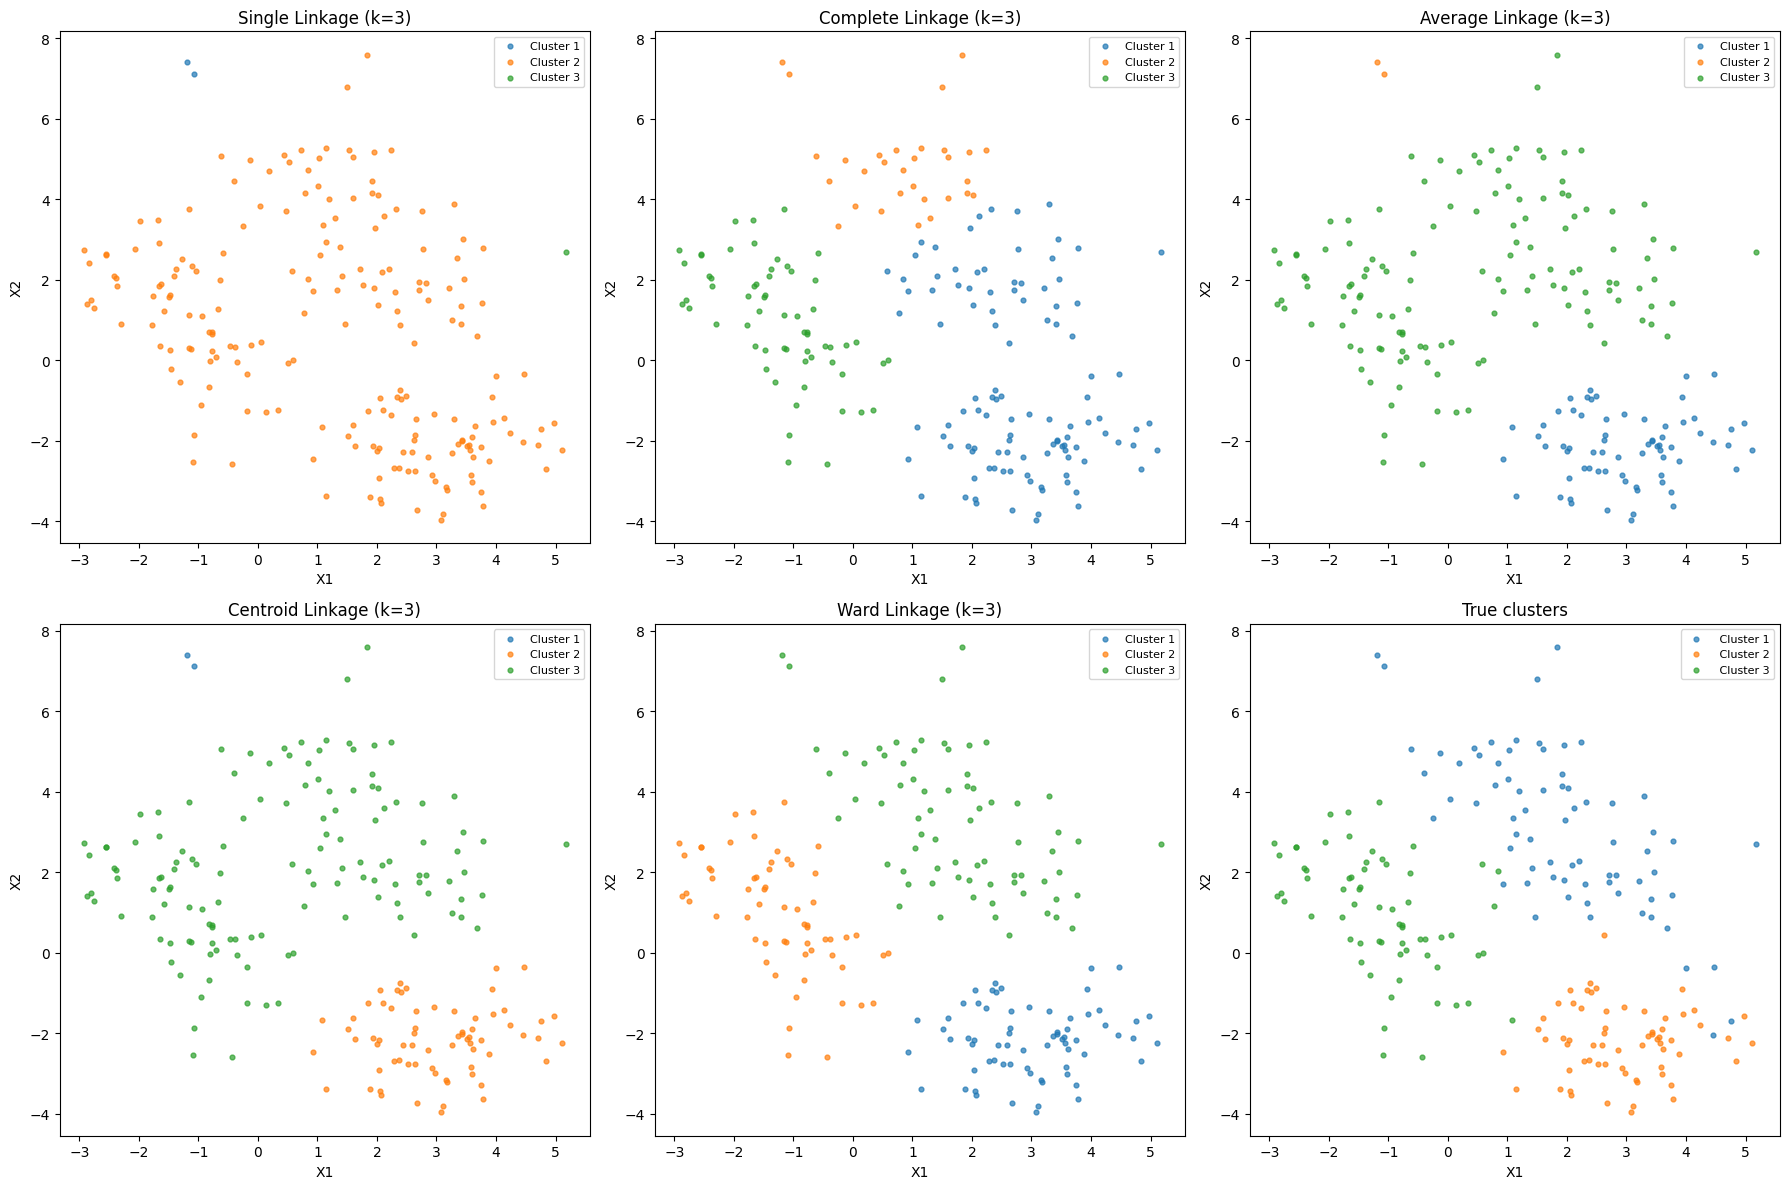

In [5]:
# --- Agglomerative (hierarchical) cluster analysis (continued)

methods = list(linkages.keys())
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

k = 3  # Number of clusters

# Scatter plots 1–5: hierarchical clustering
for i, method in enumerate(methods):
    labels = fcluster(linkages[method], t=k, criterion='maxclust')
    df_sim[f'cluster_{method}'] = labels
    
    ax = axes[i]
    for lab in sorted(set(labels)):
        sub = df_sim[df_sim[f'cluster_{method}'] == lab]
        ax.scatter(sub['X1'], sub['X2'], alpha=0.7, s=12, label=f'Cluster {lab}')
    
    ax.set_title(f'{method.capitalize()} Linkage (k={k})')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.legend(fontsize=8)

# Scatter plot 6: true clustering
ax = axes[5]
for label in sorted(df_sim['clust'].unique()):
    sub = df_sim[df_sim['clust'] == label]
    ax.scatter(sub['X1'], sub['X2'], alpha=0.7, s=12, label=f' Cluster {label}')

ax.set_title('True clusters')
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.legend(fontsize=8)

plt.tight_layout()

print("\nSimulated data with hierarchical and true cluster membership:\n")
plt.show()


**Interpretation**

Compared with the true clustering, the Ward method gives the best result, followed by the complete linkage method. The results of the other methods are less satisfactory here.   

<h3 style="color:#0050A0;">Interactive: agglomerative cluster analysis step by step</h3>

We consider a small teaching example with five objects (1 to 5) and a given object distance matrix. 

Use the **slider** (`Step`) to go through the merges; use the **dropdown** (`Linkage`) to switch the method. 

On the left, the objects and the current clusters are shown; the pending merge is marked in red. On the right, the current class distance matrix is displayed, with the smallest distance framed.

*Note:* Since object distances rather than coordinates are given, the objects (points) are arranged approximately in 2D via *Metric MDS*, with the distance matrix remaining the basis. 

In [6]:
# --- Teaching example: object distance matrix with five objects (1..5) 
D_obj = np.array([
    [0, 7, 1, 9, 8],
    [7, 0, 6, 3, 5],
    [1, 6, 0, 8, 7],
    [9, 3, 8, 0, 4],
    [8, 5, 7, 4, 0],
], dtype=float)
obj_labels = ['1', '2', '3', '4', '5']

# As only distances (no coordinates) are given: 2D layout via Metric MDS (for visualisation only)
try:    # scikit-learn >= 1.8 ("dissimilarity" was renamed to "metric")
    mds = MDS(n_components=2, metric="precomputed", init="random", random_state=42,
              n_init=4, normalized_stress=False)
except TypeError:    # scikit-learn < 1.8
    mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42,
              n_init=4, normalized_stress=False)
coords = mds.fit_transform(D_obj)

def agglomerative_run(D, linkage):
    """Agglomerative clustering on the object distance matrix D.

    Returns, for each step (frame), the current clusters, their class distance matrix
    and the pair to be merged next (smallest class distance)."""
    def class_distance(A, B):
        vals = [D[i, j] for i in A for j in B]
        if linkage == "single":    return min(vals)          # Nearest neighbour
        if linkage == "complete":  return max(vals)          # Furthest neighbour
        return sum(vals) / len(vals)                         # Average linkage

    clusters = [[i] for i in range(D.shape[0])]              # finest partition
    frames = []
    while True:
        clusters = sorted(clusters, key=lambda c: c[0])      # stable order
        m = len(clusters)
        dmat = np.zeros((m, m))
        for a in range(m):
            for b in range(a + 1, m):
                dmat[a, b] = dmat[b, a] = class_distance(clusters[a], clusters[b])
        if m == 1:                                           # coarsest partition reached
            frames.append(dict(clusters=[c[:] for c in clusters], dmat=dmat, merge=None, dist=None))
            break
        # smallest class distance -> pair to be merged (in case of a tie: smallest indices)
        best = None
        for a in range(m):
            for b in range(a + 1, m):
                if best is None or dmat[a, b] < best[0] - 1e-12:
                    best = (dmat[a, b], a, b)
        dist, a, b = best
        frames.append(dict(clusters=[c[:] for c in clusters], dmat=dmat, merge=(a, b), dist=dist))
        merged = sorted(clusters[a] + clusters[b])
        clusters = [clusters[i] for i in range(m) if i not in (a, b)] + [merged]
    return frames

def _set_str(members):
    return "{" + ",".join(str(i + 1) for i in members) + "}"

# Short self-test of the merge distances (Single 1,3,4,6 | Complete 1,3,5,9 | Average 1,3,4.5,7.5)
for _lk, _expected in [("single", [1, 3, 4, 6]), ("complete", [1, 3, 5, 9]), ("average", [1, 3, 4.5, 7.5])]:
    _got = [f["dist"] for f in agglomerative_run(D_obj, _lk) if f["merge"] is not None]
    assert _got == _expected, (_lk, _got)

In [7]:
# --- Drawing functions and interactive control 
def _draw_hier_scatter(ax, coords, frame, labels):
    clusters, merge = frame["clusters"], frame["merge"]
    for ci, c in enumerate(clusters):
        col = CLUSTER_COLORS[c[0] % len(CLUSTER_COLORS)]       # stable colour per group
        highlighted = merge is not None and ci in merge
        pts = coords[c]
        if len(c) >= 3:                                        # convex hull around the cluster
            try:
                h = ConvexHull(pts); poly = pts[h.vertices]
                ax.fill(poly[:, 0], poly[:, 1], color=col, alpha=0.13, zorder=1)
                ax.plot(np.append(poly[:, 0], poly[0, 0]), np.append(poly[:, 1], poly[0, 1]),
                        color=col, lw=3.2 if highlighted else 1.6, zorder=2)
            except Exception:
                ax.plot(pts[:, 0], pts[:, 1], color=col, lw=3.2 if highlighted else 1.6, zorder=2)
        elif len(c) == 2:                                      # line connects a pair
            ax.plot(pts[:, 0], pts[:, 1], color=col, lw=3.2 if highlighted else 1.6, zorder=2)
        ax.scatter(pts[:, 0], pts[:, 1], s=300, color=col, zorder=3,
                   edgecolors=(ACCENT_RED if highlighted else "white"),
                   linewidths=2.6 if highlighted else 1.5)
    for (x, y), lab in zip(coords, labels):
        ax.annotate(lab, (x, y), color="white", ha="center", va="center",
                    fontweight="bold", fontsize=10, zorder=4)
    if merge is not None:                                      # connection + pending distance
        a, b = merge
        ca, cb = coords[clusters[a]].mean(0), coords[clusters[b]].mean(0)
        ax.annotate("", xy=cb, xytext=ca,
                    arrowprops=dict(arrowstyle="<->", color=ACCENT_RED, lw=2, ls="--"))
        mid = (ca + cb) / 2
        u = (cb - ca) / np.linalg.norm(cb - ca)
        off = np.array([u[1], -u[0]])                          # label beside the arrow, not on
        off = off if (off[0], off[1]) >= (0, 0) else -off      # the points (to the right/top)
        ax.annotate(f"D = {frame['dist']:g}", mid, xytext=30 * off, textcoords="offset points",
                    color=ACCENT_RED, fontweight="bold", ha="center", va="center", fontsize=10,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=ACCENT_RED, alpha=0.9))
    pad = 1.0                                                  # margin: no marker is clipped
    ax.set_xlim(coords[:, 0].min() - pad, coords[:, 0].max() + pad)
    ax.set_ylim(coords[:, 1].min() - pad, coords[:, 1].max() + pad)
    ax.set_aspect("equal")
    ax.xaxis.set_minor_locator(MultipleLocator(0.5))
    ax.yaxis.set_minor_locator(MultipleLocator(0.5))
    ax.grid(which="minor", color="#ECECEC", linewidth=0.6)
    ax.grid(which="major", color="#D9D9D9", linewidth=0.9)

def _draw_hier_heatmap(ax, frame):
    clusters, dmat, merge = frame["clusters"], frame["dmat"], frame["merge"]
    clabels = [_set_str(c) for c in clusters]
    m = len(clusters)
    if m == 1:                                                 # last step: only one cluster
        ax.axis("off")
        ax.set_title(r"Class distance matrix  $D(C_i, C_j)$")
        ax.text(0.5, 0.5, "All objects now form\na single cluster", transform=ax.transAxes,
                ha="center", va="center", fontsize=12, fontweight="bold", color=PRIMARY)
        return
    sns.heatmap(dmat, mask=np.eye(m, dtype=bool), annot=True, fmt="g", cmap="Blues",
                xticklabels=clabels, yticklabels=clabels, square=True, cbar=False,
                linewidths=.5, linecolor="white", annot_kws={"fontsize": 10}, ax=ax)
    ax.set_title(r"Class distance matrix  $D(C_i, C_j)$")
    ax.tick_params(axis='x', rotation=0); ax.tick_params(axis='y', rotation=0)
    if merge is not None:                                      # frame the smallest distance
        a, b = merge
        for (r, c) in [(a, b), (b, a)]:
            ax.add_patch(Rectangle((c, r), 1, 1, fill=False, edgecolor=ACCENT_RED, lw=3))

def hier_step(step=0, linkage="single"):
    frames = agglomerative_run(D_obj, linkage.lower())
    step = int(np.clip(step, 0, len(frames) - 1))
    frame = frames[step]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4),
                                   gridspec_kw={"width_ratios": [1.15, 1]})
    _draw_hier_scatter(ax1, coords, frame, obj_labels)
    ax1.set_xlabel("MDS dimension 1"); ax1.set_ylabel("MDS dimension 2")
    ax1.set_title("Objects & current clusters")
    _draw_hier_heatmap(ax2, frame)
    partition = "   ".join(_set_str(c) for c in frame["clusters"])
    if frame["merge"] is not None:
        a, b = frame["merge"]
        head = (f"Step {step} – {linkage} linkage      Partition: {partition}\n"
                f"next merge: {_set_str(frame['clusters'][a])} $\\cup$ {_set_str(frame['clusters'][b])}"
                f"    at class distance  D = {frame['dist']:g}")
    else:
        head = f"Step {step} – {linkage} linkage      all objects merged: {partition}"
    fig.suptitle(head, fontsize=12, color=PRIMARY, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

# Interactive display of the hierarchical cluster analysis
interact(hier_step,
         step=IntSlider(value=0, min=0, max=4, step=1, description="Step"),
         linkage=Dropdown(options=["Single", "Complete", "Average"], value="Single",
                          description="Linkage"));

interactive(children=(IntSlider(value=0, description='Step', max=4), Dropdown(description='Linkage', options=(…


 Simulated data with k-means clustering and true cluster membership:



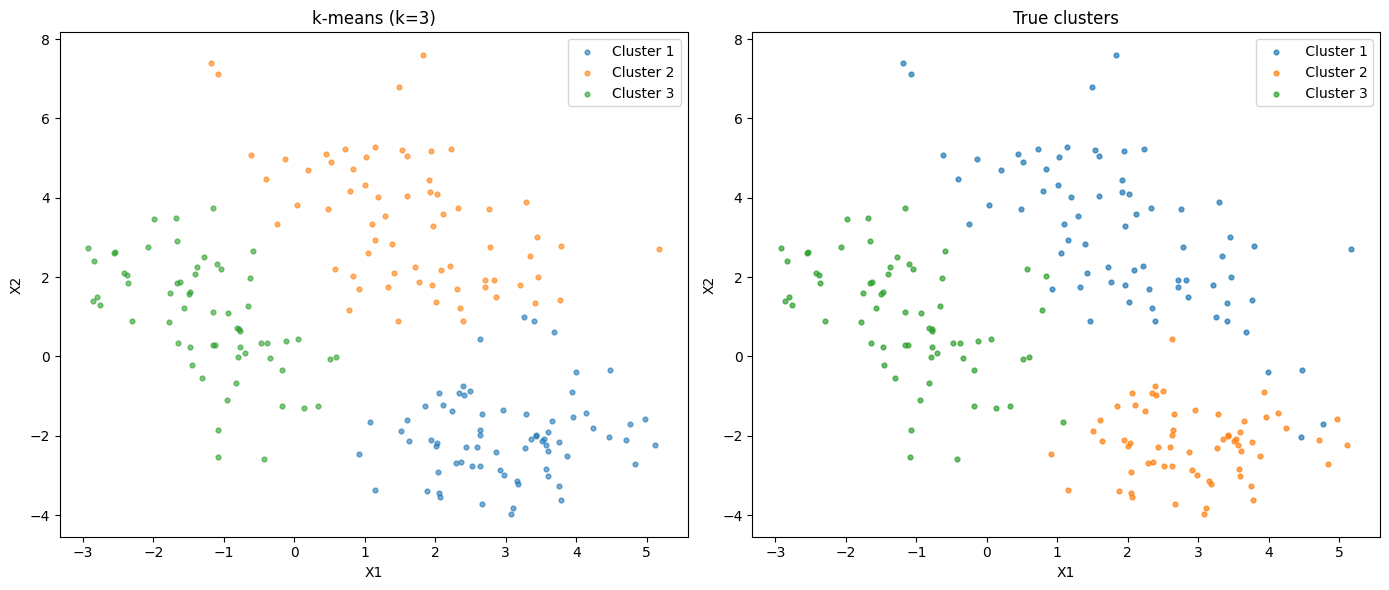

In [8]:
# --- k-means clustering

# k-means algorithm with k=3 clusters 
km = KMeans(n_clusters=3, n_init=20, max_iter=1000, random_state=2025)
km_labels = km.fit_predict(X_std)
df_sim['kmeans_cluster'] = km_labels + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot 1: k-means clustering
ax = axes[0]
for lab in sorted(df_sim['kmeans_cluster'].unique()):
    sub = df_sim[df_sim['kmeans_cluster'] == lab]
    ax.scatter(sub['X1'], sub['X2'], label=f'Cluster {lab}', alpha=0.6, s=12)
ax.set_title('k-means (k=3)')
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.legend()

# Scatter plot 2: true clustering
ax = axes[1]
for label in sorted(df_sim['clust'].unique()):
    sub = df_sim[df_sim['clust'] == label]
    ax.scatter(sub['X1'], sub['X2'], label=f' Cluster {label}', alpha=0.7, s=12)
ax.set_title('True clusters')
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.legend()
plt.tight_layout()

#plt.savefig("sim_data_k-means.png", dpi=300, bbox_inches="tight")

print("\n Simulated data with k-means clustering and true cluster membership:\n")
plt.show()


**Interpretation**

The k-means algorithm also yields a clustering in which only a few objects are assigned to the wrong cluster. 

**Task**

Repeat the analysis with simulated data in which the clusters are less neatly shaped.

<h3 style="color:#0050A0;">Interactive: k-means algorithm step by step</h3>

We generate different 2D datasets and carry out the k-means algorithm step by step: 

- **Step 0**: Random initial partition and cluster centres (★).
- **Odd steps**: (b) Each point is assigned to the nearest centre (recolouring).
- **Even steps**: (a) The centres are recalculated (grey arrows show the shift).
- **Last step**: The partition no longer changes.
  
The sliders can be used to change the **number of clusters** $k$ and the **seed** (the random initial partition); the **dropdown** switches the dataset. 

With *moons*/*circles*, you can see that k-means reaches its limits with *non-convex* clusters. 
By changing the *seed*, you can see that the algorithm only finds a *local minimum* of the variance criterion (Within-Cluster Sum of Squares, WCSS).

In [9]:
# --- k-means step by step
def make_dataset(name):
    """Fixed 2D dataset (random_state fixes the data; the k-means seed
    below only controls the random initial partition)."""
    if name == "moons":
        X, _ = make_moons(n_samples=120, noise=0.08, random_state=42)
    elif name == "circles":
        X, _ = make_circles(n_samples=120, noise=0.06, factor=0.5, random_state=42)
    else:
        X, _ = make_blobs(n_samples=120, centers=3, cluster_std=1.0, random_state=42)
    return X


def run_kmeans_frames(X, k, seed, max_iter=30):
    """k-means by hand. One frame per sub-step:
    init -> (b assign, a recalculate) repeated -> done."""
    rloc = np.random.default_rng(seed)
    n = len(X)
    labels = rloc.integers(0, k, size=n)                       # random initial partition
    for c in range(k):                                         # no empty cluster
        if not np.any(labels == c):
            labels[rloc.integers(0, n)] = c

    def centroids(lab, prev):
        return np.array([X[lab == c].mean(0) if np.any(lab == c) else prev[c] for c in range(k)])

    def wcss(lab, cs):                                         # variance criterion (Within-Cluster Sum of Squares)
        return float(sum(((X[lab == c] - cs[c]) ** 2).sum() for c in range(k) if np.any(lab == c)))

    cents = centroids(labels, None)
    frames = [dict(labels=labels.copy(), cents=cents.copy(), old=None, sub="init",
                   it=0, wcss=wcss(labels, cents))]
    it = 0
    while it < max_iter:
        it += 1
        d2 = ((X[:, None, :] - cents[None, :, :]) ** 2).sum(2)  # (b) assign to the nearest centre
        new = d2.argmin(1)
        frames.append(dict(labels=new.copy(), cents=cents.copy(), old=None, sub="b",
                           it=it, wcss=wcss(new, cents)))
        old = cents.copy()                                     # (a) recalculate the centres
        cents = centroids(new, cents)
        frames.append(dict(labels=new.copy(), cents=cents.copy(), old=old, sub="a",
                           it=it, wcss=wcss(new, cents)))
        if np.array_equal(new, labels):                        # partition unchanged -> stop
            break
        labels = new
    last = frames[-1]
    frames.append(dict(labels=last["labels"].copy(), cents=last["cents"].copy(), old=None,
                       sub="done", it=it, wcss=last["wcss"]))
    return frames


def _kmeans_title(frame, step):
    w = frame["wcss"]
    if frame["sub"] == "init":
        t = "Step 0 – random initial partition & centres"
    elif frame["sub"] == "b":
        t = f"Step {step} – (b) assign each point to the nearest centre"
    elif frame["sub"] == "a":
        t = f"Step {step} – (a) recalculate the centres (arrows show the shift)"
    else:
        t = f"Converged after {frame['it']} iteration(s) – final clustering"
    return f"{t}\nVariance criterion (WCSS) = {w:,.1f}"


def kmeans_demo(step=0, k=3, seed=0, dataset="blobs"):
    X = make_dataset(dataset)
    frames = run_kmeans_frames(X, k, seed)
    step = int(np.clip(step, 0, len(frames) - 1))
    frame = frames[step]
    pad = 0.6
    xlim = (X[:, 0].min() - pad, X[:, 0].max() + pad)
    ylim = (X[:, 1].min() - pad, X[:, 1].max() + pad)
    lab, cents = frame["labels"], frame["cents"]
    fig, ax = plt.subplots(figsize=(7.6, 6.2))
    for c in range(k):
        pts = X[lab == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=24, alpha=.75, edgecolors="none",
                   color=CLUSTER_COLORS[c % len(CLUSTER_COLORS)], label=f"Cluster {c + 1}")
    if frame["old"] is not None:
        for c in range(k):
            ax.annotate("", xy=cents[c], xytext=frame["old"][c],
                        arrowprops=dict(arrowstyle="->", color=GRAY_TEXT, lw=1.8))
    ax.scatter(cents[:, 0], cents[:, 1], marker="*", s=200, zorder=5,
               c=[CLUSTER_COLORS[c % len(CLUSTER_COLORS)] for c in range(k)],
               edgecolors="black", linewidths=1.3, label="Centres")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
    ax.set_title(_kmeans_title(frame, step))
    ax.legend(loc="upper right", fontsize=8, framealpha=.9)
    fig.tight_layout(); plt.show()


# Interactive display of the k-means cluster analysis
interact(kmeans_demo,
         step=IntSlider(value=0, min=0, max=45, step=1, description="Step"),
         k=IntSlider(value=3, min=2, max=5, step=1, description="k"),
         seed=IntSlider(value=0, min=0, max=9, step=1, description="Seed"),
         dataset=Dropdown(options=["blobs", "moons", "circles"], value="blobs",
                          description="Dataset"));

interactive(children=(IntSlider(value=0, description='Step', max=45), IntSlider(value=3, description='k', max=…


Scree plot for the k-means algorithm to determine the number of clusters (hyperparameter):



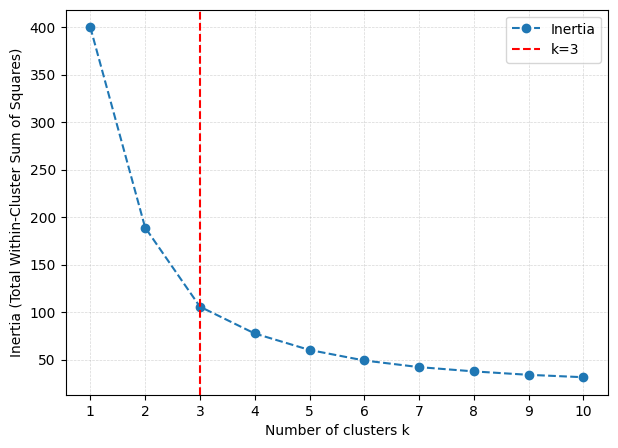

In [10]:
# Excursus: graphical determination of the number of clusters (hyperparameter)

max_k = 10 # Maximum number of clusters
inertia = []

# Compute k-means for k = 1..max_k
for k in range(1, max_k + 1):
    km = KMeans(n_clusters=k, n_init=20, max_iter=100, random_state=2025)
    km.fit(X_std)
    inertia.append(km.inertia_)

# Scree plot with a line at k=3
plt.figure(figsize=(7,5))
plt.plot(range(1, max_k + 1), inertia, marker='o', linestyle='--', label='Inertia')
plt.axvline(x=3, color='red', linestyle='--', label='k=3')
plt.xticks(range(1, max_k + 1))
plt.xlabel('Number of clusters k')
plt.ylabel('Inertia (Total Within-Cluster Sum of Squares)')
plt.title('')
plt.legend()
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

print("\nScree plot for the k-means algorithm to determine the number of clusters (hyperparameter):\n")
plt.show()

**Excursus**

If the actual number of clusters is not known, it has to be specified as a hyperparameter of the algorithm. The *scree plot* shows from which number of clusters onwards (here k=3) the total sum of squared deviations within the clusters decreases only marginally. 

<div style="border:0px; background-color:#0050A0; width:100%; height:1px;">&nbsp;</div>
<h2 style="color:#0050A0;">Part 2 on cluster analysis – actuarial case study</h2>

The case study uses a portfolio of 50,000 life insurance policies (file `data/cluster_vec_050Tsd.txt`, one row per policy); background: portfolio consolidation in the Module 6 slides. The columns keep their original German abbreviations. Only two of them are used below: **VS** = sum insured (*Versicherungssumme*) and **DK_sald** = reserve (*Deckungskapital*).

In [11]:
# --- Load the portfolio data

# The data file is read from the folder data/ next to the notebook; if it is missing
# (e.g. in Google Colab), it is downloaded once from the course repository
# (REPO_RAW, see the setup at the top).
from pathlib import Path
from urllib.request import urlretrieve

data_file = Path("data") / "cluster_vec_050Tsd.txt"
if not data_file.exists():
    data_file.parent.mkdir(exist_ok=True)
    print(f"Downloading {data_file.name} from the course repository ...")
    urlretrieve(f"{REPO_RAW}/data/{data_file.name}", data_file.with_suffix(".part"))
    data_file.with_suffix(".part").replace(data_file)

pf_data = pd.read_csv(data_file, sep="\t")
pf_data = pf_data.dropna(axis=1, how="all") 

# Number of rows and columns 
print("\nNumber of rows:", pf_data.shape[0])
print("\nNumber of columns:", pf_data.shape[1])

# First rows 
print("\nFirst rows of the data table:\n")
display(pf_data.head())



Number of rows: 50000

Number of columns: 16

First rows of the data table:



,VTRNR,VTRANZ,DK_sald,VS,Beitrag,Restlaufzeit,Vers.Art,Rech.Zins,Rest-BZD,BonSum,VA,Bon-DK,FLV-Guth,SUEA,ZW-Typ,Laufzeit
0,85867565577,1,2348.72,2984.00,0.00,132,1,0.0400,132,0.0,639.0,0,0.00,0.0,12,252
1,85805558587,1,2993.16,7942.41,306.84,240,1,0.0350,240,0.0,0.0,0,0.00,367.0,12,420
2,85805591587,1,-143.73,5113.00,526.68,240,1,0.0275,240,0.0,0.0,0,0.00,0.0,12,240
3,85806665587,1,0.00,30677.50,1227.12,84,4,0.0300,84,0.0,0.0,0,26815.20,0.0,12,300
4,85800835507,1,0.00,5396.00,0.00,72,4,0.0400,72,0.0,0.0,0,6319.74,0.0,12,144



Scatter plot of the columns 'VS' and 'DK_sald':



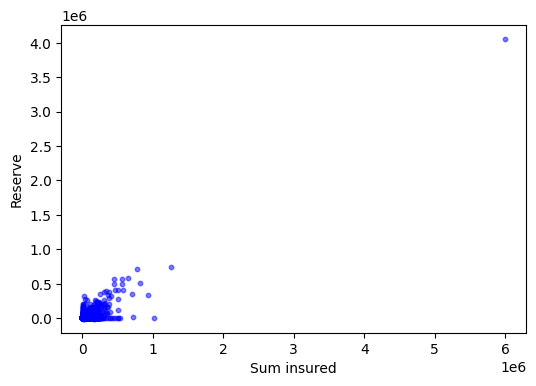

In [12]:
# --- Selection of two columns: "VS" and "DK_sald"

# We only consider "VS" and "DK_sald"
plt.figure(figsize=(6,4))
plt.scatter(pf_data['VS'], pf_data['DK_sald'], c='blue', s=10, alpha=0.5)
plt.xlabel('Sum insured')
plt.ylabel('Reserve')
plt.title('')

print("\nScatter plot of the columns 'VS' and 'DK_sald':\n")
plt.show()



Scatter plot of the columns 'VS' and 'DK_sald' for 'VS <10,000' and 'DK_sald<100,000':



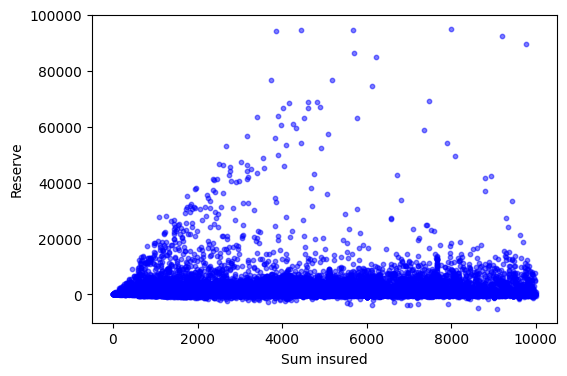

In [13]:
# --- Zoom into the lower left area of the scatter plot

pf_data_filt = pf_data[(pf_data['VS'] < 10000) & (pf_data['DK_sald'] < 100000)]
plt.figure(figsize=(6,4))
plt.scatter(pf_data_filt['VS'], pf_data_filt['DK_sald'], c='blue', s=10, alpha=0.5)
plt.xlabel('Sum insured')
plt.ylabel('Reserve')
plt.title('')

print("\nScatter plot of the columns 'VS' and 'DK_sald' for 'VS <10,000' and 'DK_sald<100,000':\n")
plt.show()


Scatter plot of the standardised columns 'VS' and 'DK_sald':



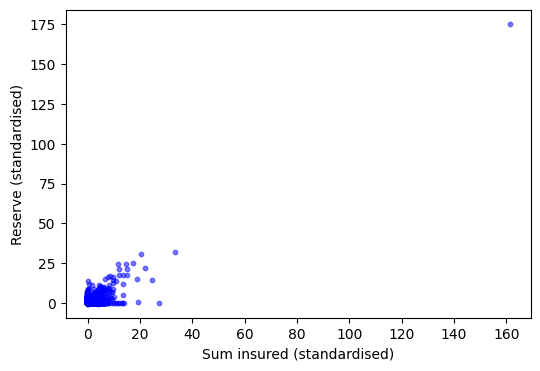


Zoom into the scatter plot of the standardised columns 'VS' and 'DK_sald' for values < 20:



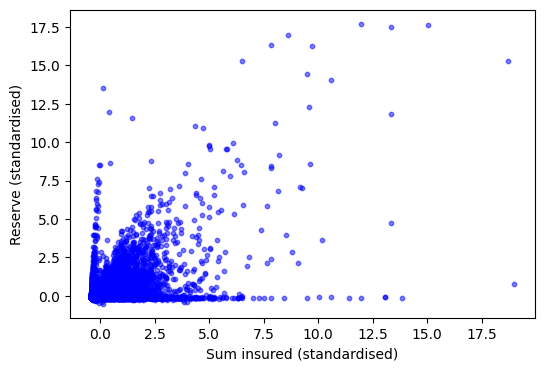

In [14]:
# --- Standardisation as preparation for the cluster analysis

scaler = StandardScaler()
X_stand = scaler.fit_transform(pf_data[['VS', 'DK_sald']])

# Visualisation of the standardised values
plt.figure(figsize=(6,4))
plt.scatter(X_stand[:,0], X_stand[:,1], c='blue', s=10, alpha=0.5)

plt.xlabel('Sum insured (standardised)')
plt.ylabel('Reserve (standardised)')
plt.title('')

print("\nScatter plot of the standardised columns 'VS' and 'DK_sald':\n")
plt.show()  

# --- Zoom in on the lower left area of the scatter plot
thres = 20

X_stand_filt = X_stand[(X_stand[:,0] < thres) & (X_stand[:,1] < thres)]
plt.figure(figsize=(6,4))
plt.scatter(X_stand_filt[:,0], X_stand_filt[:,1], c='blue', s=10, alpha=0.5)
plt.xlabel('Sum insured (standardised)')
plt.ylabel('Reserve (standardised)')
plt.title('')

print(f"\nZoom into the scatter plot of the standardised columns 'VS' and 'DK_sald' for values < {thres}:\n")
plt.show()



In [15]:
# --- k-means clustering 

k = 50 # Number of clusters (hyperparameter)
km = KMeans(n_clusters=k, n_init=20, max_iter=100, random_state=2025)
km.fit(X_stand)

centers = km.cluster_centers_      # Cluster centres
labels = km.labels_                # Cluster labels
sizes = np.bincount(labels)        # Cluster sizes


In [16]:
# --- Output the results

print(f"\nNumber of iterations: {km.n_iter_}")

print("\nSize of the clusters:\n ")
for i, s in enumerate(sizes):
    print(f"Cluster {i:2d}: {s:5d} elements")

print("\nCluster centres (first 5 rows):")
print(pd.DataFrame(centers).round(4).head())

print(f"\nTotal Within-Cluster Sum of Squares (Inertia): {km.inertia_:,.2f}")


Number of iterations: 23

Size of the clusters:
 
Cluster  0:  6946 elements
Cluster  1:     1 elements
Cluster  2:    21 elements
Cluster  3:    72 elements
Cluster  4:     4 elements
Cluster  5:  1010 elements
Cluster  6:   100 elements
Cluster  7:  2479 elements
Cluster  8:    23 elements
Cluster  9:    16 elements
Cluster 10:     5 elements
Cluster 11:  8991 elements
Cluster 12:     1 elements
Cluster 13:    51 elements
Cluster 14:    60 elements
Cluster 15:   325 elements
Cluster 16:     1 elements
Cluster 17:   175 elements
Cluster 18:     2 elements
Cluster 19:    92 elements
Cluster 20:  4361 elements
Cluster 21:   176 elements
Cluster 22:  1556 elements
Cluster 23:     3 elements
Cluster 24:  1023 elements
Cluster 25:    15 elements
Cluster 26:     9 elements
Cluster 27:     9 elements
Cluster 28:     4 elements
Cluster 29: 10053 elements
Cluster 30:     1 elements
Cluster 31:   649 elements
Cluster 32:     1 elements
Cluster 33:     9 elements
Cluster 34:   257 elements
Clus


Scatter plot of the standardised columns 'VS' and 'DK_sald' and k-means cluster centres (k=50):



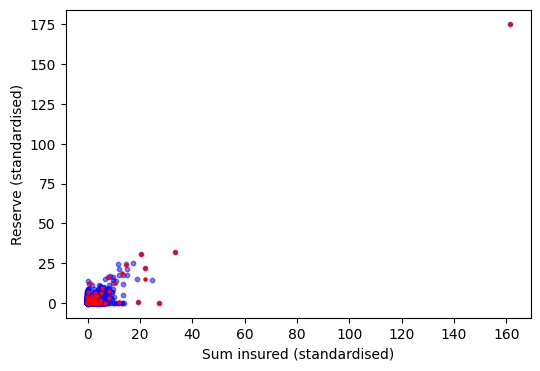

In [17]:
# --- Visualisation of the cluster centres

plt.figure(figsize=(6,4))
plt.scatter(X_stand[:,0], X_stand[:,1], c='blue', s=10, alpha=0.5)
plt.scatter(centers[:,0], centers[:,1], c='red', s=5)

plt.xlabel('Sum insured (standardised)')
plt.ylabel('Reserve (standardised)')
plt.title('')

print(f"\nScatter plot of the standardised columns 'VS' and 'DK_sald' and k-means cluster centres (k={k}):\n")
plt.show()



Zoom into the scatter plot of the standardised columns 'VS' and 'DK_sald' for values < 20 and k-means cluster centres (k=50):



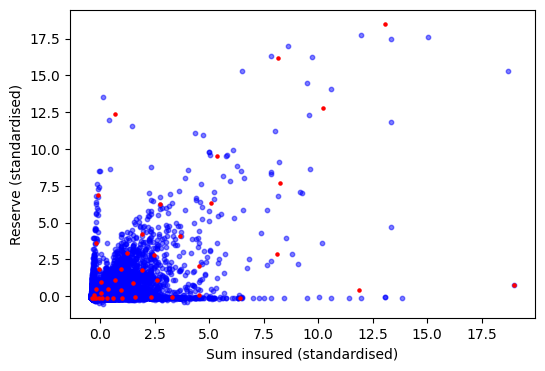

In [18]:
# --- Zoom into the lower left area of the scatter plot

thres = 20

plt.figure(figsize=(6,4))
mask = (X_stand[:,0] < thres) & (X_stand[:,1] < thres)
plt.scatter(X_stand[mask,0], X_stand[mask,1], c='blue', s=10, alpha=0.5)

mask_centers = (centers[:, 0] < thres) & (centers[:, 1] < thres)
plt.scatter(centers[mask_centers, 0], centers[mask_centers, 1], c='red', s=5)

plt.xlabel('Sum insured (standardised)')
plt.ylabel('Reserve (standardised)')
plt.title('')

#plt.savefig("real_data_k-means.png", dpi=300, bbox_inches="tight")

print(f"\nZoom into the scatter plot of the standardised columns 'VS' and 'DK_sald' for values < {thres} and k-means cluster centres (k={k}):\n")
plt.show()


In [19]:
# Excursus: graphical determination of the number of clusters (hyperparameter)

max_k = 50 # Maximum number of clusters
inertia = []

# Compute k-means for k = 1..max_k
for k in range(1, max_k + 1):
    km = KMeans(n_clusters=k, n_init=20, max_iter=100, random_state=2025)
    km.fit(X_stand)
    inertia.append(km.inertia_)



Scree plot for the k-means algorithm to determine the number of clusters (hyperparameter):



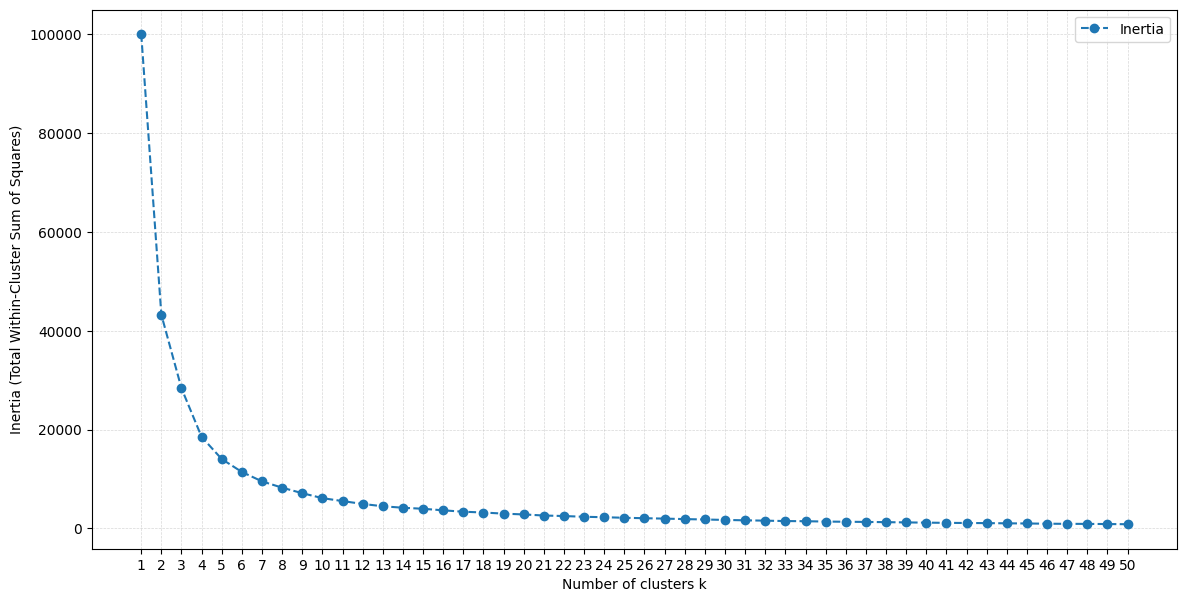

In [20]:
# Scree plot 
plt.figure(figsize=(14,7))
plt.plot(range(1, max_k + 1), inertia, marker='o', linestyle='--', label='Inertia')
plt.xticks(range(1, max_k + 1))
plt.xlabel('Number of clusters k')
plt.ylabel('Inertia (Total Within-Cluster Sum of Squares)')
plt.title('')
plt.legend()
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

print("\nScree plot for the k-means algorithm to determine the number of clusters (hyperparameter):\n")
plt.show()

<h2 style="color:#0050A0;">Appendix: What can go wrong?</h2>

A classic pitfall with the k-means algorithm is **missing standardisation**. 

Background: k-means is based on (squared) Euclidean distances; features with a large spread of values then dominate the distance calculation, regardless of their substantive relevance.

We can see this directly in the portfolio data: the *sum insured (VS)* and the *reserve (DK_sald)* lie on different scales (see the spreads printed below the figure). 

We apply k-means (below with, e.g., $k=6$ clusters) once *without* and once *with* standardisation and display both assignments in the *standardised* space (where the distances can be compared fairly). 

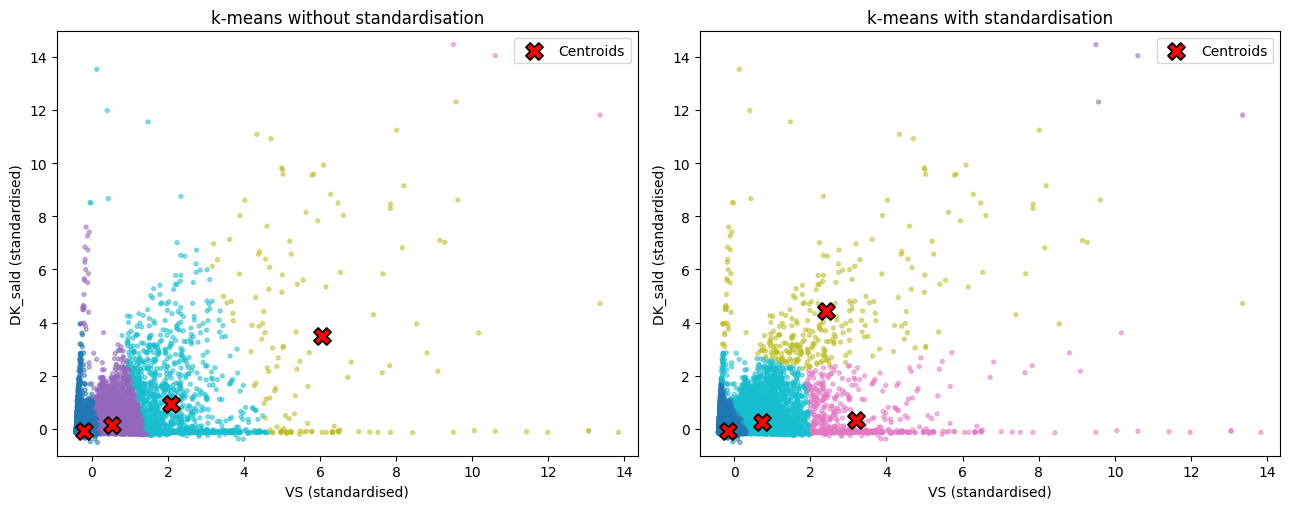

                              VS    DK_sald
Standard deviation        37,119     23,110
Interquartile range       12,252      1,362
Minimum                        1     -8,783
Maximum                6,000,000  4,056,830

With k=6 clusters: without standardisation, k-means effectively slices the
space along only one axis (VS, the feature with the larger spread, dominates), and
the centroids line up; with standardisation, on the other hand, compact, balanced
clusters emerge.


In [21]:
# Pitfall: k-means without vs. with standardisation
X_raw = pf_data[['VS', 'DK_sald']].values
scaler = StandardScaler().fit(X_raw)
X_pf_std = scaler.transform(X_raw)   # for a fair comparison / for display

k_pf = 6
km_raw = KMeans(n_clusters=k_pf, n_init=20, max_iter=100, random_state=2025).fit(X_raw)  # WITHOUT standardisation
km_std = KMeans(n_clusters=k_pf, n_init=20, max_iter=100, random_state=2025).fit(X_pf_std)  # WITH standardisation
lab_raw, lab_std = km_raw.labels_, km_std.labels_

# Bring the cluster centres into the standardised space for a fair display
cent_raw = scaler.transform(km_raw.cluster_centers_)   # Centres from the raw-data clustering
cent_std = km_std.cluster_centers_                     # Centres already in the standardised space

# Display both assignments in the standardised space (zoom in on the dense area)
thres = 15
mask = (X_pf_std[:, 0] < thres) & (X_pf_std[:, 1] < thres)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, lab, cent, title in [(axes[0], lab_raw, cent_raw, 'k-means without standardisation'),
                             (axes[1], lab_std, cent_std, 'k-means with standardisation')]:
    ax.scatter(X_pf_std[mask, 0], X_pf_std[mask, 1], c=lab[mask], cmap='tab10', s=8, alpha=0.5)
    ax.scatter(cent[:, 0], cent[:, 1], c='red', marker='X', s=150,
               edgecolors='black', linewidths=1.3, zorder=5, label='Centroids')
    ax.set_xlabel('VS (standardised)')
    ax.set_ylabel('DK_sald (standardised)')
    ax.set_title(title)
    ax.set_xlim(X_pf_std[mask, 0].min() - 0.5, X_pf_std[mask, 0].max() + 0.5)
    ax.set_ylim(X_pf_std[mask, 1].min() - 0.5, X_pf_std[mask, 1].max() + 0.5)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

# The spreads (standard deviation, interquartile range) illustrate why VS dominates without
# standardisation; the ranges (minimum to maximum) alone are of a similar order
iqr = np.percentile(X_raw, 75, axis=0) - np.percentile(X_raw, 25, axis=0)
print(f"{'':21}{'VS':>11}{'DK_sald':>11}")
print(f"{'Standard deviation':21}{X_raw[:,0].std():>11,.0f}{X_raw[:,1].std():>11,.0f}")
print(f"{'Interquartile range':21}{iqr[0]:>11,.0f}{iqr[1]:>11,.0f}")
print(f"{'Minimum':21}{X_raw[:,0].min():>11,.0f}{X_raw[:,1].min():>11,.0f}")
print(f"{'Maximum':21}{X_raw[:,0].max():>11,.0f}{X_raw[:,1].max():>11,.0f}")

print(f"\nWith k={k_pf} clusters: without standardisation, k-means effectively slices the")
print("space along only one axis (VS, the feature with the larger spread, dominates), and")
print("the centroids line up; with standardisation, on the other hand, compact, balanced")
print("clusters emerge.")
